# Ocean acidification: pH projections

Surface ocean pH projections averaged over each Pacific EEZ and ocean region from two sources: the CMIP6 members of the IPCC-WGI AR6 Interactive Atlas (global warming levels, box plots across models) and the decadal carbonate-system projections of Jiang et al. (2023).

```{glue:figure} ph_fig
:scale: 60%
:align: center
```

**Figure. Change in surface pH relative to 2015–2035 in each Pacific EEZ at the global warming levels** (multi-model median, `map_scenario`).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels use `map_scenario`; box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Surface pH at global warming levels (IPCC Atlas, CMIP6)

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,10,-0.0123,-0.0135,-0.0112,-0.0138,-0.0108
1,North Pacific Subtropical Gyre,SSP245,+2.0°C,2052,10,-0.0656,-0.0685,-0.0632,-0.0704,-0.0628
2,North Pacific Subtropical Gyre,SSP245,+2.5°C,2079,10,-0.1139,-0.1168,-0.1117,-0.1229,-0.1113
3,North Pacific Subtropical Gyre,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP370,+1.5°C,2030,9,-0.0138,-0.0145,-0.0117,-0.0151,-0.0109
5,North Pacific Subtropical Gyre,SSP370,+2.0°C,2046,9,-0.0660,-0.0674,-0.0648,-0.0682,-0.0646
6,North Pacific Subtropical Gyre,SSP370,+2.5°C,2061,9,-0.1179,-0.1218,-0.1163,-0.1228,-0.1158
7,North Pacific Subtropical Gyre,SSP370,+3.0°C,2075,9,-0.1668,-0.1725,-0.1666,-0.1764,-0.1664
8,North Pacific Subtropical Gyre,SSP585,+1.5°C,2027,10,-0.0049,-0.0060,-0.0040,-0.0067,-0.0038
9,North Pacific Subtropical Gyre,SSP585,+2.0°C,2041,10,-0.0543,-0.0560,-0.0530,-0.0572,-0.0524


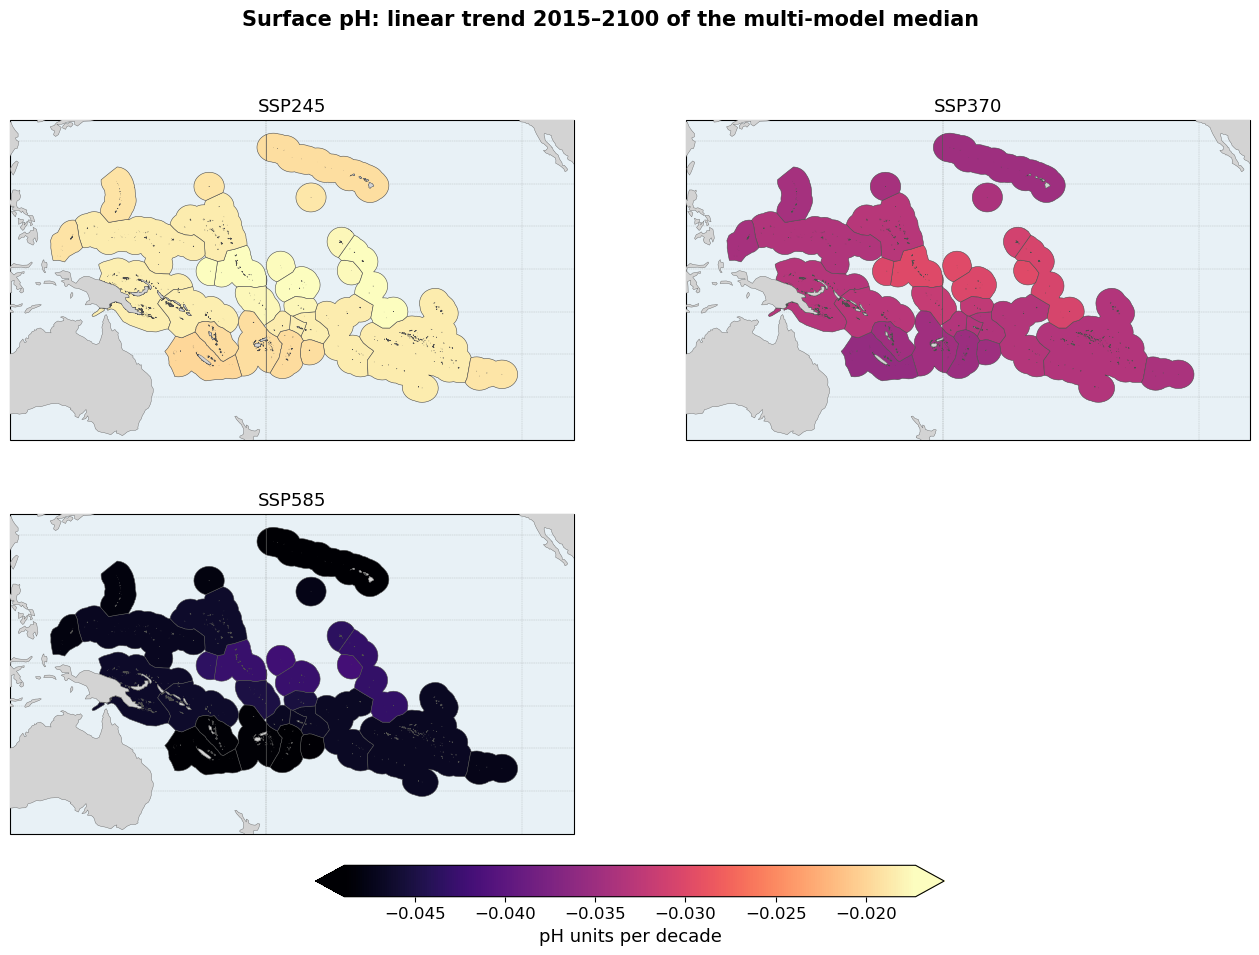

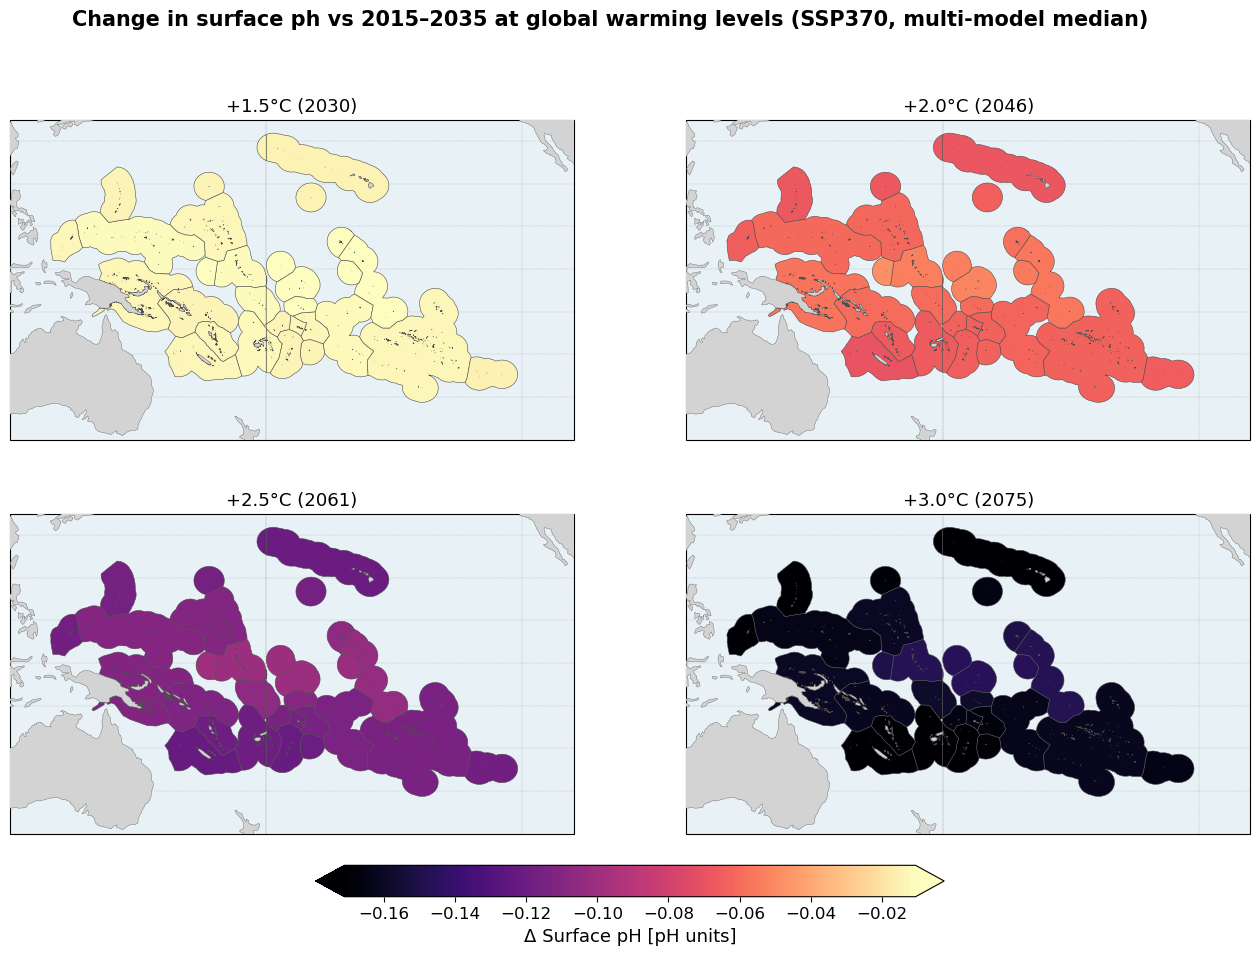

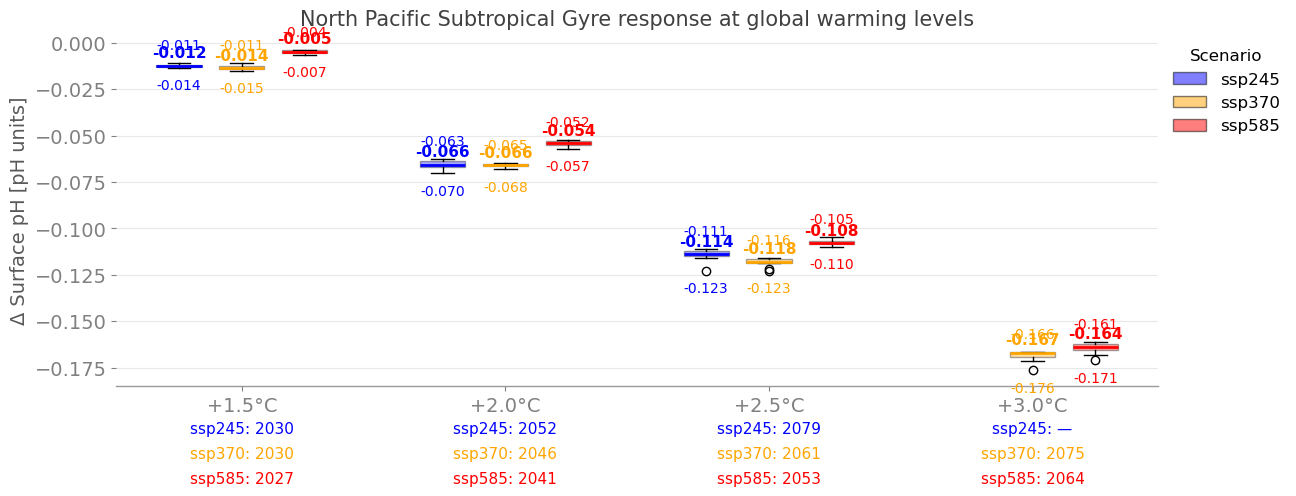

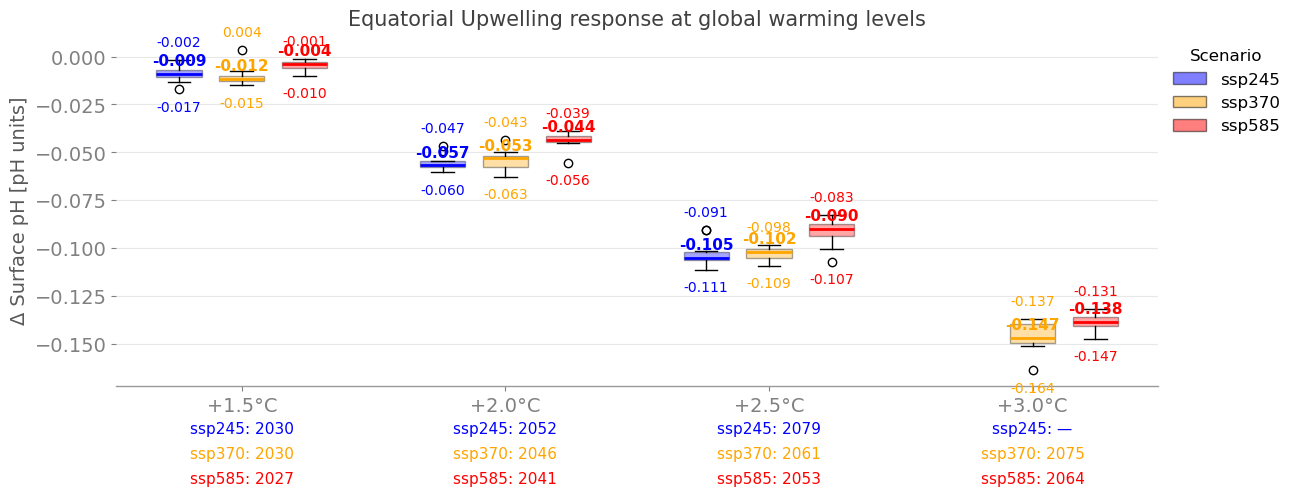

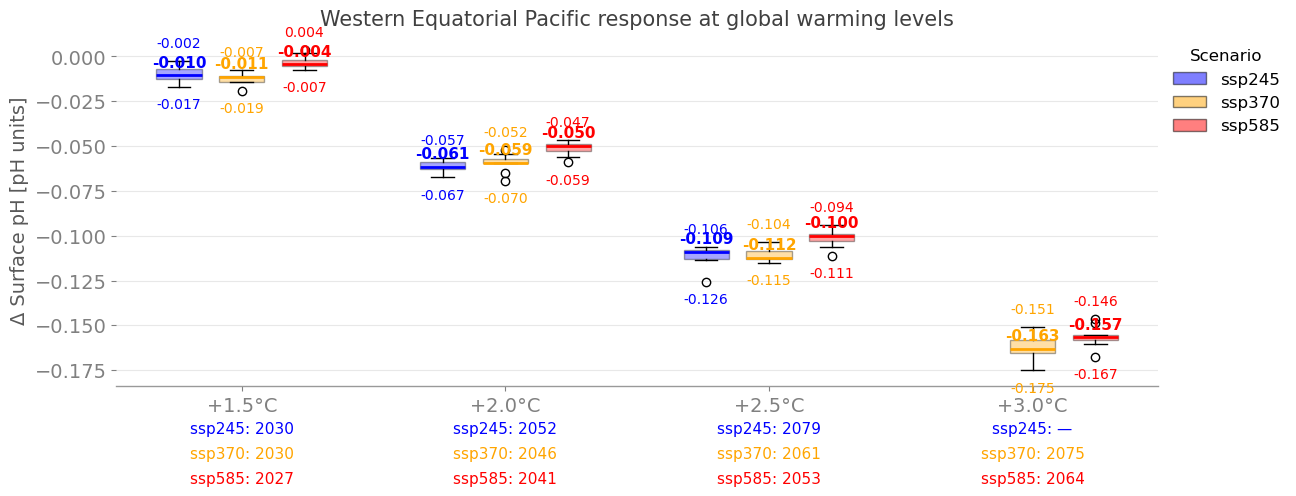

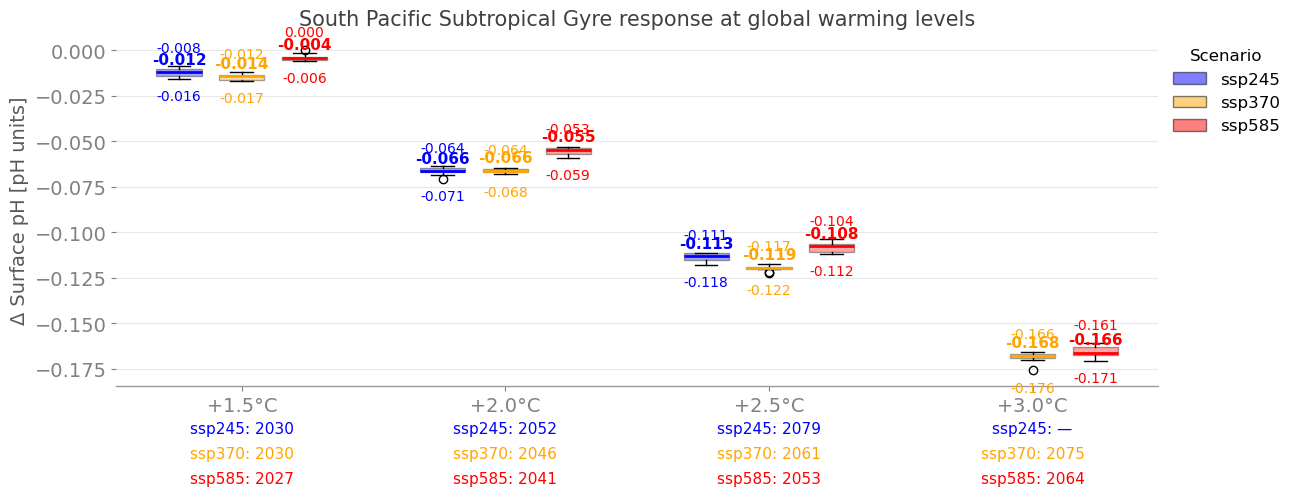

In [4]:
ds_ph = reg.extract_atlas_ph_regional(eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds_ph, "ph", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
glue("ph_fig", figs["levels"], display=False)
tables["regions"]

## Surface pH by decade (Jiang et al., 2023)

Decadal projections of the surface ocean carbonate system on a 1° grid (median of the CMIP6 Earth system models; [Jiang et al., 2023](https://www.ncei.noaa.gov/data/oceans/ncei/ocads/metadata/0259391.html)), averaged over each EEZ and ocean region. The product has no individual models, so the regions are shown as decadal series instead of box plots.

In [5]:
ssp_scenarios_ocads = ["ssp126", "ssp245", "ssp370", "ssp585"]

scenario                             ssp126  ssp245  ssp370  ssp585
region                         Year                                
Equatorial Upwelling           2020  7.9967  7.9966  7.9955  7.9954
                               2030  7.9809  7.9779  7.9769  7.9750
                               2040  7.9612  7.9528  7.9450  7.9417
                               2050  7.9488  7.9311  7.9147  7.9043
                               2060  7.9464  7.9142  7.8883  7.8663
                               2070  7.9425  7.8955  7.8542  7.8157
                               2080  7.9451  7.8811  7.8222  7.7633
                               2090  7.9467  7.8703  7.7884  7.7092
                               2100  7.9644  7.8738  7.7661  7.6716
North Pacific Subtropical Gyre 2020  8.0512  8.0513  8.0508  8.0509
                               2030  8.0309  8.0273  8.0236  8.0218
                               2040  8.0118  8.0008  7.9895  7.9844
                               2050  8.0032  7.9788  7.9587  7.9442
                               2060  7.9982  7.9573  7.9245  7.8953
                               2070  7.9977  7.9400  7.8899  7.8435
                               2080  8.0025  7.9275  7.8567  7.7884
                               2090  8.0080  7.9158  7.8185  7.7295
                               2100  8.0194  7.9151  7.7893  7.6848
South Pacific Subtropical Gyre 2020  8.0796  8.0781  8.0792  8.0783
                               2030  8.0559  8.0530  8.0491  8.0489
                               2040  8.0413  8.0296  8.0192  8.0141
                               2050  8.0312  8.0068  7.9861  7.9721
                               2060  8.0250  7.9843  7.9512  7.9232
                               2070  8.0268  7.9672  7.9182  7.8705
                               2080  8.0306  7.9538  7.8847  7.8149
                               2090  8.0390  7.9471  7.8518  7.7632
                               2100  8.0460  7.9430  7.8140  7.7114
Western Equatorial Pacific     2020  8.0356  8.0380  8.0346  8.0373
                               2030  8.0172  8.0170  8.0114  8.0122
                               2040  7.9971  7.9896  7.9776  7.9759
                               2050  7.9909  7.9700  7.9507  7.9387
                               2060  7.9856  7.9484  7.9181  7.8925
                               2070  7.9834  7.9308  7.8834  7.8391
                               2080  7.9869  7.9180  7.8522  7.7881
                               2090  7.9951  7.9109  7.8199  7.7351
                               2100  7.9989  7.9035  7.7796  7.6815

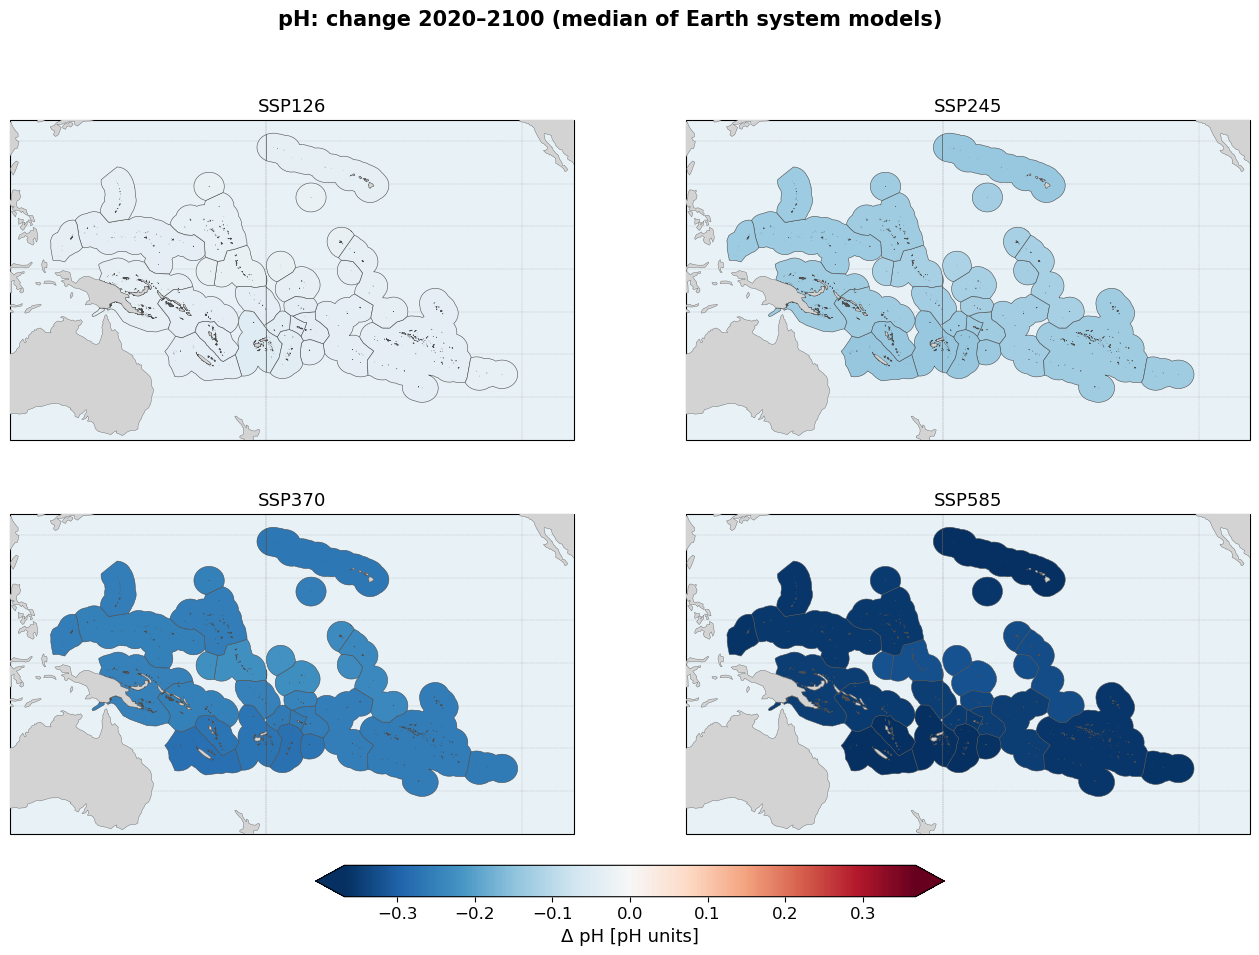

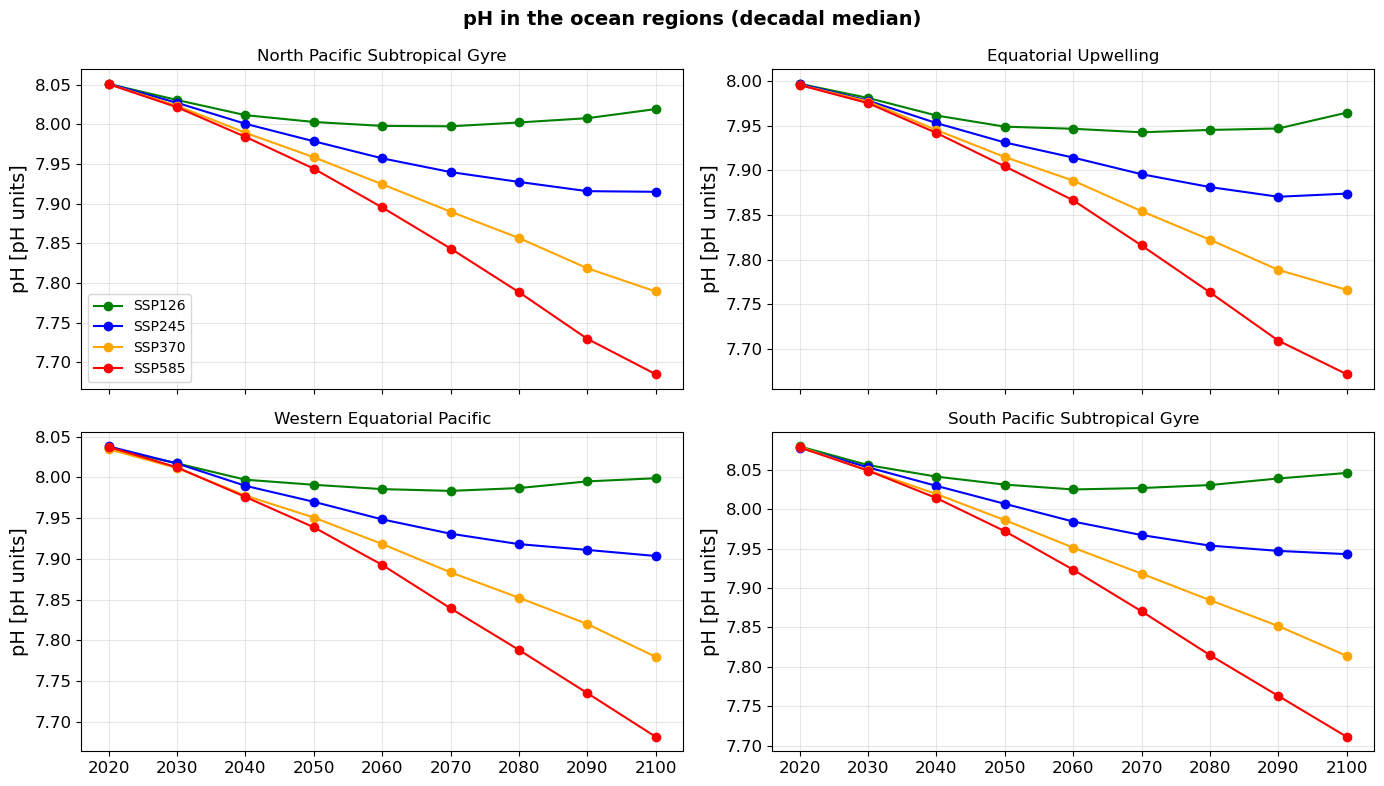

In [6]:
ds_ocads = reg.extract_ocads_regional("pHT", eez, ssp_scenarios_ocads)
figs, tables = reg.ocads_report(ds_ocads, "pHT", "pH", "pH units", eez, ssp_scenarios_ocads, fig_dir, tables_dir, cmap="RdBu_r")
tables["regions"]